# Statistical and Machine Learning — HW1 : Introduction and Learnability

**Université de Haute-Alsace — M2 Informatique et Mobilité**

**Module :** Statistical and Machine Learning

**Teacher :** Ali El Hadi ISMAIL FAWAZ

**Student :** Zainab ELAMRI

---

**Goal.** Compare the **PAC** setting (labels are always correct) and the **Agnostic PAC** setting (some labels are flipped) with a simple ERM algorithm for threshold classifiers on $[0, 1]$:

$$h_t(x) = \begin{cases} 1 & \text{if } x > t \\ 0 & \text{otherwise} \end{cases}$$

The target is $f_\theta = h_\theta$ with an unknown threshold $\theta$. No machine learning library is used.

## 0. Parameters

| Parameter | Value | Why |
|---|---|---|
| Target threshold $\theta$ | 0.37 | Any value in $(0,1)$ works; we avoid 0.5 so the problem is not symmetric. |
| Accuracy $\varepsilon$ | 0.05 | We accept a true error of at most 5 %. |
| Confidence $\delta$ | 0.05 | The "bad event" $L(h) > \varepsilon$ should happen in at most 5 % of the runs. |
| Noise rate $\eta$ | 0.2 | 20 % of the labels are flipped; clearly larger than $\varepsilon$, so the difference between both settings is visible. |
| Training sizes $m$ | 5, 10, 20, 50, 100, 200 | Given in the subject. |
| Repetitions | 500 | Enough to estimate a probability (standard error $\le 0.023$). |
| Test set size | 10 000 | Large enough to estimate the true error (standard error $\le 0.005$). |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)      # fixed seed -> reproducible results

THETA  = 0.37                       # target threshold
EPS    = 0.05                       # accuracy parameter epsilon
DELTA  = 0.05                       # confidence parameter delta
ETA    = 0.2                        # label noise rate (agnostic setting)
M_LIST = [5, 10, 20, 50, 100, 200]  # training set sizes
N_REP  = 500                        # number of repetitions
N_TEST = 10_000                     # size of the test set

## 1. Data Generation

Each $x$ is drawn uniformly in $[0,1]$ and gets the label $y = f_\theta(x)$.
In the agnostic setting, each label is then flipped with probability $\eta$.

In [2]:
def generate_data(m, eta=0.0):
    '''Draw m points uniformly in [0,1] and label them with f_theta.
    Each label is flipped with probability eta (eta = 0: realizable setting).'''
    x = rng.uniform(0, 1, m)
    y = (x > THETA).astype(int)            # y = f_theta(x)
    flip = rng.uniform(0, 1, m) < eta      # which labels are flipped
    y[flip] = 1 - y[flip]
    return x, y

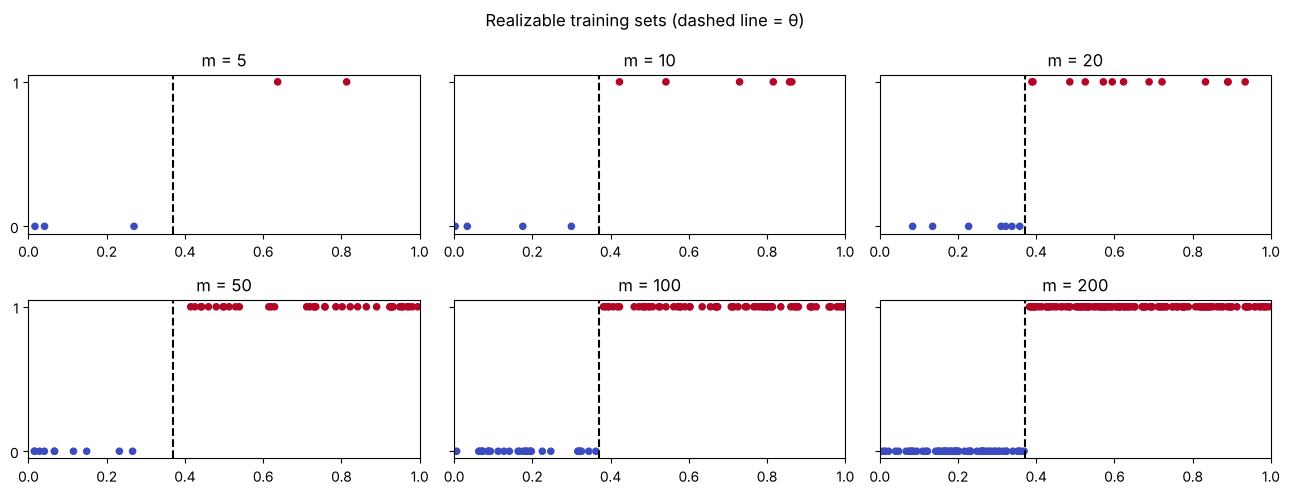

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharey=True)
for ax, m in zip(axes.ravel(), M_LIST):
    x, y = generate_data(m)
    ax.scatter(x, y, c=y, cmap="coolwarm", s=20)
    ax.axvline(THETA, color="k", ls="--")
    ax.set_title(f"m = {m}")
    ax.set_xlim(0, 1); ax.set_yticks([0, 1])
fig.suptitle("Realizable training sets (dashed line = θ)")
plt.tight_layout(); plt.show()

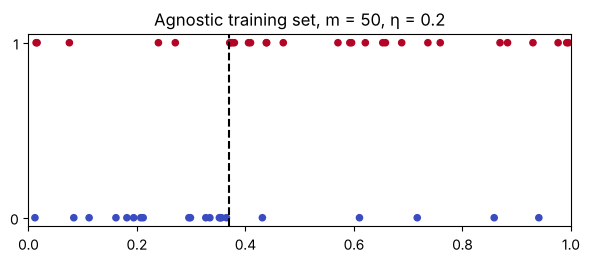

In [4]:
# Same idea with noisy labels (m = 50)
x, y = generate_data(50, eta=ETA)
plt.figure(figsize=(7, 2.5))
plt.scatter(x, y, c=y, cmap="coolwarm", s=20)
plt.axvline(THETA, color="k", ls="--")
plt.title(f"Agnostic training set, m = 50, η = {ETA}")
plt.yticks([0, 1]); plt.xlim(0, 1); plt.show()

**Comment.** Without noise, all points left of $\theta$ have label 0 and all points right of $\theta$ have label 1, so a perfect threshold always exists. With noise, some points have the "wrong" label on each side of $\theta$, so no threshold can separate the two classes perfectly.

## 2. Implementation of ERM

ERM chooses the threshold with the **smallest empirical error** (the fraction of misclassified training points).

**Strategy.** The empirical error only changes when $t$ crosses a training point. So we do not need to test every real number: it is enough to test $t = 0$ (everything predicted 1) and $t = x_i$ for each training point. This gives the $m + 1$ possible classifications of the sample, so the minimum found is the exact ERM. If several thresholds have the same error, we keep the first (smallest) one.

In [5]:
def predict(t, x):
    '''Threshold classifier h_t.'''
    return (x > t).astype(int)

def error(t, x, y):
    '''Fraction of points misclassified by h_t.'''
    return np.mean(predict(t, x) != y)

def erm(x, y):
    '''Return the threshold with the smallest empirical error, and this error.'''
    candidates = np.concatenate(([0.0], np.sort(x)))
    errors = [error(t, x, y) for t in candidates]
    best = np.argmin(errors)
    return candidates[best], errors[best]

# Small example
x, y = generate_data(10)
t_hat, e_hat = erm(x, y)
print(f"Learned threshold: {t_hat:.3f} (true theta = {THETA}), empirical error = {e_hat}")

Learned threshold: 0.243 (true theta = 0.37), empirical error = 0.0


## 3. Performance Evaluation

* **Empirical error** $L_S(h)$: error on the training set.
* **True error** $L_\mathcal{D}(h)$: estimated on a large test set of 10 000 new points, generated independently from the same distribution.

In [6]:
x_test, y_test = generate_data(N_TEST)

print(f"{'m':>4} | {'threshold':>9} | {'empirical error':>15} | {'true error':>10}")
for m in M_LIST:
    x, y = generate_data(m)
    t_hat, e_emp = erm(x, y)
    e_true = error(t_hat, x_test, y_test)
    print(f"{m:>4} | {t_hat:9.3f} | {e_emp:15.3f} | {e_true:10.3f}")

   m | threshold | empirical error | true error
   5 |     0.266 |           0.000 |      0.103
  10 |     0.116 |           0.000 |      0.253
  20 |     0.348 |           0.000 |      0.023
  50 |     0.355 |           0.000 |      0.017
 100 |     0.367 |           0.000 |      0.003
 200 |     0.366 |           0.000 |      0.004


**Comment.** The empirical error is always 0: ERM always finds a threshold that classifies the training set perfectly. The true error is not 0, because the learned threshold is not exactly $\theta$. It is the largest point with label 0, which is a bit to the left of $\theta$. The more points we have, the closer this point is to $\theta$, so the true error decreases with $m$.

On a single training set the result depends on luck (here $m = 10$ is worse than $m = 5$, because no point fell close to $\theta$). This is why, in the next section, we repeat each experiment many times.

## 4. Experimental Verification of PAC Learning

For each $m$ we repeat the experiment 500 times (new training set each time) and count how often the true error is larger than $\varepsilon$. This estimates $\Pr(L(h) > \varepsilon)$.

In [7]:
def run_experiment(eta):
    '''For each m: repeat N_REP times, return the empirical and true errors.'''
    x_test, y_test = generate_data(N_TEST, eta)
    results = {}
    for m in M_LIST:
        emp, true = [], []
        for _ in range(N_REP):
            x, y = generate_data(m, eta)
            t_hat, e_emp = erm(x, y)
            emp.append(e_emp)
            true.append(error(t_hat, x_test, y_test))
        results[m] = (np.array(emp), np.array(true))
    return results

res_pac = run_experiment(eta=0.0)

print(f"{'m':>4} | {'mean emp. error':>15} | {'mean true error':>15} | {'Pr(L > eps)':>11}")
for m in M_LIST:
    emp, true = res_pac[m]
    print(f"{m:>4} | {emp.mean():15.3f} | {true.mean():15.3f} | {np.mean(true > EPS):11.3f}")

   m | mean emp. error | mean true error | Pr(L > eps)
   5 |           0.000 |           0.156 |       0.756
  10 |           0.000 |           0.091 |       0.638
  20 |           0.000 |           0.047 |       0.348
  50 |           0.000 |           0.022 |       0.080
 100 |           0.000 |           0.010 |       0.002
 200 |           0.000 |           0.005 |       0.000


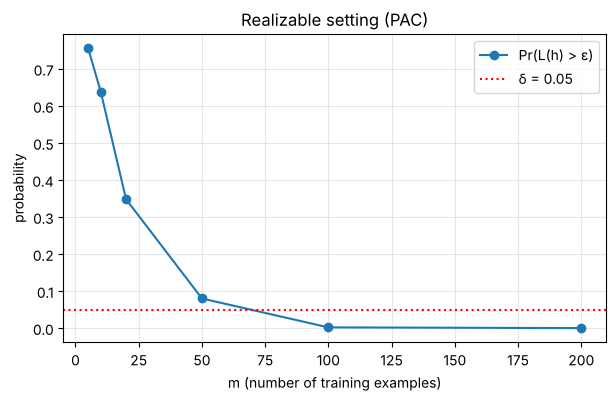

In [8]:
p_pac = [np.mean(res_pac[m][1] > EPS) for m in M_LIST]
plt.figure(figsize=(7, 4))
plt.plot(M_LIST, p_pac, "o-", label="Pr(L(h) > ε)")
plt.axhline(DELTA, color="red", ls=":", label="δ = 0.05")
plt.xlabel("m (number of training examples)"); plt.ylabel("probability")
plt.title("Realizable setting (PAC)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Comment.** The probability that the learned classifier has an error larger than $\varepsilon = 5\%$ decreases quickly when $m$ grows: about 76 % for $m = 5$, 35 % for $m = 20$, 8 % for $m = 50$ and almost 0 for $m \ge 100$. It is below $\delta = 5\%$ from $m = 100$.

This is exactly the PAC guarantee: with enough examples, the learned classifier is **Probably** (probability $\ge 1-\delta$) **Approximately Correct** (error $\le \varepsilon$). The class of threshold classifiers is PAC learnable, and ERM is a good learner in the realizable setting.

## 5. From PAC to Agnostic PAC

We repeat the same experiments with $\eta = 0.2$ (20 % of the labels flipped, in the training and the test sets).
The best possible classifier is still $h_\theta$, but now even $h_\theta$ makes an error of $\eta = 0.2$, because of the noise. So the smallest error we can hope for is $\min_h L_\mathcal{D}(h) = \eta$.

In [9]:
x_test_noisy, y_test_noisy = generate_data(N_TEST, ETA)
print("Single training sets with noise:")
print(f"{'m':>4} | {'threshold':>9} | {'empirical error':>15} | {'true error':>10}")
for m in M_LIST:
    x, y = generate_data(m, ETA)
    t_hat, e_emp = erm(x, y)
    print(f"{m:>4} | {t_hat:9.3f} | {e_emp:15.3f} | {error(t_hat, x_test_noisy, y_test_noisy):10.3f}")

Single training sets with noise:
   m | threshold | empirical error | true error
   5 |     0.701 |           0.200 |      0.390
  10 |     0.188 |           0.200 |      0.311
  20 |     0.297 |           0.050 |      0.245
  50 |     0.267 |           0.180 |      0.262
 100 |     0.368 |           0.220 |      0.197
 200 |     0.362 |           0.200 |      0.202


In [10]:
res_agn = run_experiment(eta=ETA)

print(f"{'m':>4} | {'mean emp.':>9} | {'mean true':>9} | {'Pr(emp = 0)':>11} | {'Pr(L > eps)':>11} | {'Pr(L > eta + eps)':>17}")
for m in M_LIST:
    emp, true = res_agn[m]
    print(f"{m:>4} | {emp.mean():9.3f} | {true.mean():9.3f} | {np.mean(emp == 0):11.3f} | "
          f"{np.mean(true > EPS):11.3f} | {np.mean(true > ETA + EPS):17.3f}")

   m | mean emp. | mean true | Pr(emp = 0) | Pr(L > eps) | Pr(L > eta + eps)
   5 |     0.114 |     0.327 |       0.508 |       1.000 |             0.760
  10 |     0.139 |     0.288 |       0.216 |       1.000 |             0.584
  20 |     0.170 |     0.261 |       0.022 |       1.000 |             0.442
  50 |     0.189 |     0.227 |       0.000 |       1.000 |             0.168
 100 |     0.194 |     0.213 |       0.000 |       1.000 |             0.042
 200 |     0.198 |     0.206 |       0.000 |       1.000 |             0.004


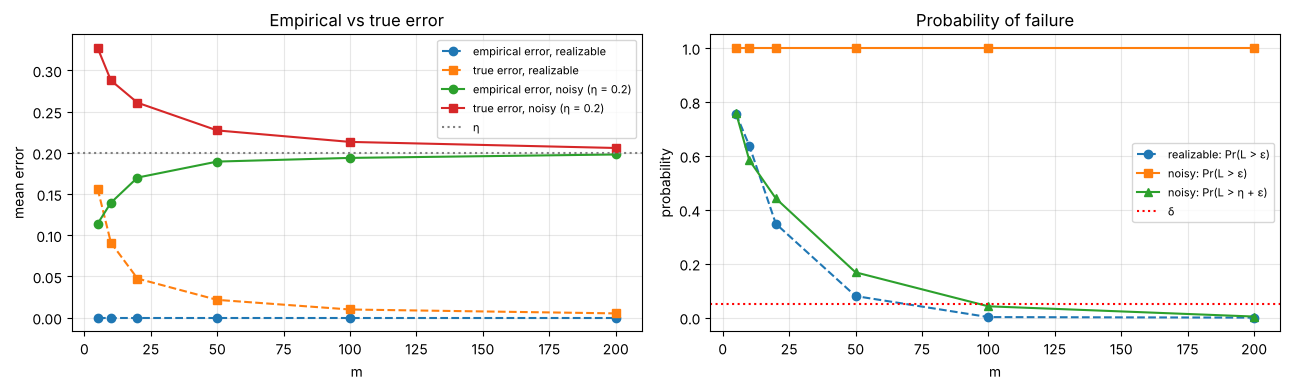

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: empirical and true errors
for res, name, style in [(res_pac, "realizable", "--"), (res_agn, f"noisy (η = {ETA})", "-")]:
    axes[0].plot(M_LIST, [res[m][0].mean() for m in M_LIST], "o" + style, label=f"empirical error, {name}")
    axes[0].plot(M_LIST, [res[m][1].mean() for m in M_LIST], "s" + style, label=f"true error, {name}")
axes[0].axhline(ETA, color="gray", ls=":", label="η")
axes[0].set_xlabel("m"); axes[0].set_ylabel("mean error"); axes[0].set_title("Empirical vs true error")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

# Right: probability of failure
axes[1].plot(M_LIST, p_pac, "o--", label="realizable: Pr(L > ε)")
axes[1].plot(M_LIST, [np.mean(res_agn[m][1] > EPS) for m in M_LIST], "s-", label="noisy: Pr(L > ε)")
axes[1].plot(M_LIST, [np.mean(res_agn[m][1] > ETA + EPS) for m in M_LIST], "^-", label="noisy: Pr(L > η + ε)")
axes[1].axhline(DELTA, color="red", ls=":", label="δ")
axes[1].set_xlabel("m"); axes[1].set_ylabel("probability"); axes[1].set_title("Probability of failure")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Discussion

**1. Can the empirical error still reach zero?**
Only by chance, with very few examples: about 51 % of the runs for $m = 5$, 22 % for $m = 10$, 2 % for $m = 20$, and never for $m \ge 50$. With more points, there are always some flipped labels on both sides of $\theta$, and no threshold can classify them all correctly. The empirical error then gets close to $\eta = 0.2$.
When the empirical error is 0 with noise, it is not a good sign: the classifier has learned the noise (overfitting), and its true error is still above 0.2.

**2. Does increasing the number of training examples still improve the generalization performance?**
Yes, but the true error no longer goes to 0. It decreases from about 0.33 ($m = 5$) to 0.21 ($m = 200$) and gets closer and closer to $\eta = 0.2$. This 20 % cannot be avoided: even the perfect threshold $\theta$ is wrong on the flipped labels.
So $\Pr(L > \varepsilon)$ stays equal to 1 for every $m$, but $\Pr(L > \eta + \varepsilon)$ decreases to 0 (below $\delta$ from $m = 100$). Learning still improves, but towards the best possible error, and more slowly than without noise: for the same $m$ the failure probability is higher (for $m = 50$: 17 % with noise vs 8 % without; for $m = 100$: 4.2 % vs 0.2 %).

**3. How do your observations relate to the PAC and Agnostic PAC learning frameworks introduced during the lectures?**
* **PAC** assumes the labels are given by a hypothesis of the class (realizable case), so the best error is 0, and asks for $L(h) \le \varepsilon$ with probability $\ge 1 - \delta$. This works in our noiseless experiments.
* With noise, the realizable assumption is false. The PAC requirement $L(h) \le \varepsilon$ is impossible to reach, whatever the number of examples, as shown by the curve stuck at 1.
* **Agnostic PAC** only asks to be close to the best hypothesis of the class: $L(h) \le \min_{h'} L(h') + \varepsilon$, here $L(h) \le 0.2 + 0.05$, with probability $\ge 1 - \delta$. This is what we observe: ERM satisfies it when $m$ is large enough.
* The noise makes learning harder: for the same $m$ the probability of failure is higher, so more examples are needed for a given $(\varepsilon, \delta)$, as predicted by the course (the agnostic sample complexity is larger than the realizable one).

## Conclusion

| | PAC (no noise) | Agnostic PAC (noise $\eta = 0.2$) |
|---|---|---|
| Best possible error | 0 | $\eta = 0.2$ |
| Empirical error of ERM | always 0 | 0 only by chance for small $m$, then close to 0.2 |
| True error when $m$ grows | goes to 0 | goes to 0.2 |
| Goal | $L(h) \le \varepsilon$ | $L(h) \le \min L + \varepsilon$ |
| Reached? | yes, from $m = 100$ | $L(h) \le \varepsilon$: never; $L(h) \le \eta + \varepsilon$: yes, from $m = 100$ (but with a higher failure probability) |

In the **PAC** setting, the learner can become almost perfect if it has enough examples. In the **Agnostic PAC** setting, the noise makes perfection impossible, so the goal becomes to be almost as good as the best possible classifier. More examples still help in both cases, but with noise more examples are needed.